# **CS 5361/6361 Machine Learning**

**Linear and Logistic Regression with Tensorflow**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 4/6/2026<br>

The tensorflow library allows flexible and very efficient implementations of models consisting of sequences of linear operations (matrix multiplication) and non-linear operations (such as sigmoid). Gradient computations are performed automatically and several optimization algorithms are provided to optimize model parameters. Several loss functions (such as mean squared error, mean absolute error, and cross entropy) are also provided.

In this notebook we will see how to implement linear and logistic regression with tensorflow using the sequential model class, which allows to easily define sequences of operations that extract an output from an input.

Import libraries

In [27]:
import tensorflow as tf
import numpy as np
import os
import distutils
import matplotlib.pyplot as plt
from keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.activations import *
from keras.utils import plot_model
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
import time

Function to plot loss and accuracy of the models during training.

In [28]:
def plot_results(history):
  fig, ax = plt.subplots()
  ax.plot(history.history['accuracy'],label = 'train')
  ax.plot(history.history['val_accuracy'],label = 'test')
  ax.set_title('Accuracy')
  ax.legend(loc='lower right')
  fig, ax = plt.subplots()
  ax.plot(history.history['loss'],label = 'train')
  ax.plot(history.history['val_loss'],label = 'test')
  ax.set_title('Loss')
  ax.legend(loc='upper right')

In [29]:
def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()

Load, scale and reshape the data.

In [30]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1)
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)

# Convert y to one-hot
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

# **Linear Regression**

Model definition

In [31]:
def linear_regression(n_inputs=784, n_outputs=10):
  # Define a sequential model, initially containing no operations
  model = tf.keras.models.Sequential()
  # Add an input layer, which specifies the dimensionality of the input data
  model.add(Input((n_inputs,)))
  # Add a dense layer, which implements the function y = np.matmul(X*W) + b
  # The number number of inputs is the number of outputs of the previous layer
  # and the number number of outputs is provided as a parameter
  model.add(Dense(n_outputs))    # In the example, W is 784-by-10, and b is (10,)
  return model

Model creation

In [32]:
model = linear_regression(x_train.shape[1], y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(optimizer=tf.keras.optimizers.Adam(),  loss="mse", metrics=["accuracy"])               # Specify optimizer (optional) and loss function

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

We can show a graphical representation of the operations to be performed by the model. In this case we have a single layer with 784 inputs and 10 outputs.

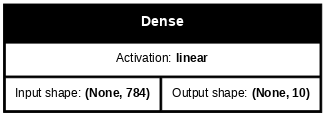

In [33]:
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64) # Graphical depiction of mode

Training the model. As with Sklearn, the fit function finds the parameters of the model that best fit the training data. Optionally, we can evaluate performance on the test (or validation) data as we train.

Results are similar to those of the Sklearn implementation.

Epoch 1/40
60/60 - 2s - 28ms/step - accuracy: 0.4873 - loss: 0.1113 - val_accuracy: 0.7396 - val_loss: 0.0641
Epoch 2/40
60/60 - 0s - 4ms/step - accuracy: 0.7792 - loss: 0.0568 - val_accuracy: 0.8113 - val_loss: 0.0509
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.8154 - loss: 0.0490 - val_accuracy: 0.8334 - val_loss: 0.0466
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.8283 - loss: 0.0457 - val_accuracy: 0.8383 - val_loss: 0.0443
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.8356 - loss: 0.0439 - val_accuracy: 0.8445 - val_loss: 0.0428
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.8390 - loss: 0.0426 - val_accuracy: 0.8487 - val_loss: 0.0419
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.8421 - loss: 0.0418 - val_accuracy: 0.8502 - val_loss: 0.0413
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.8438 - loss: 0.0411 - val_accuracy: 0.8516 - val_loss: 0.0406
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.8467 - loss: 0.0407 - val_accuracy: 0.8499 - val_loss: 0.0404
Epoch 10/40
60/60 

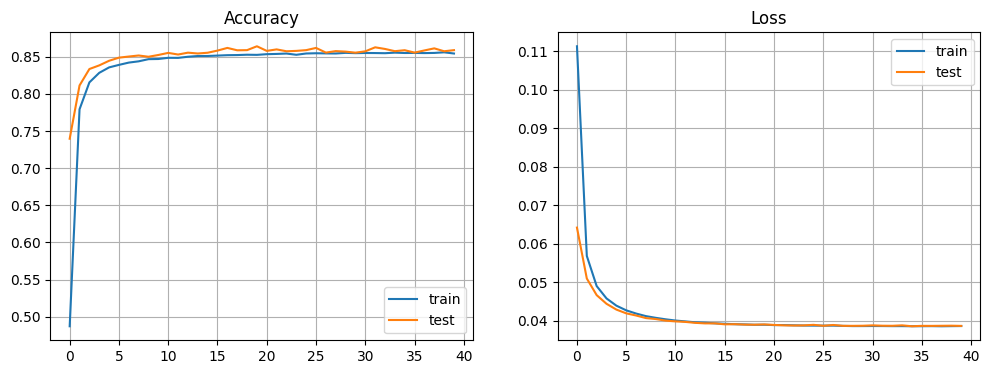

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Elapsed time training= 12.6053 secs
Accuracy = 0.8588
Confusion matrix
[[ 944    0    1    2    2    8   13    2    7    1]
 [   0 1108    3    2    2    1    5    2   12    0]
 [  17   66  806   29   15    0   35   19   39    6]
 [   4   16   21  894    4   15    7   18   21   10]
 [   0   21    7    1  878    5   11    2   11   46]
 [  19   19    5   85   23  649   20   14   39   19]
 [  16   11   13    0   20   23  868    0    7    0]
 [   5   46   15    8   23    1    1  878    0   51]
 [  12   49    8   33   26   42   14   11  758   21]
 [  15   10    3   19   77    1    1   74    4  805]]


In [34]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs =40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


# **Logistic Regression**

We can add the softmax operation as an additional layer in the model.

In [35]:
def logistic_regression(n_inputs, n_outputs):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(n_outputs))
  model.add(Softmax())
  # The dense and softmax operations can be combined into a single layer
  # model.add(Dense(n_outputs,activation = "softmax"))
  return model

Typically, we use the categorical cross entropy loss function, instead of mean-squared error.

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_4 (Softmax)             │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

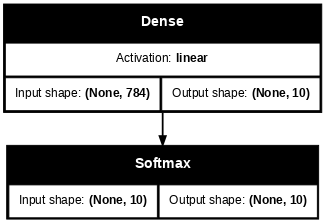

In [36]:
model = logistic_regression(x_train.shape[1], y_train.shape[1])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(), loss="CategoricalCrossentropy", metrics=["accuracy"])
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64)

We will now fit the model. Again, results are similar to those obtained by Sklearn.

Epoch 1/40
60/60 - 2s - 33ms/step - accuracy: 0.6661 - loss: 1.3966 - val_accuracy: 0.8295 - val_loss: 0.8593
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.8400 - loss: 0.7277 - val_accuracy: 0.8668 - val_loss: 0.5916
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.8655 - loss: 0.5599 - val_accuracy: 0.8874 - val_loss: 0.4893
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.8799 - loss: 0.4819 - val_accuracy: 0.8942 - val_loss: 0.4338
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.8882 - loss: 0.4360 - val_accuracy: 0.9010 - val_loss: 0.3987
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.8946 - loss: 0.4050 - val_accuracy: 0.9037 - val_loss: 0.3746
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.8997 - loss: 0.3826 - val_accuracy: 0.9067 - val_loss: 0.3569
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9032 - loss: 0.3658 - val_accuracy: 0.9084 - val_loss: 0.3429
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9059 - loss: 0.3523 - val_accuracy: 0.9095 - val_loss: 0.3333
Epoch 10/40
60/60 

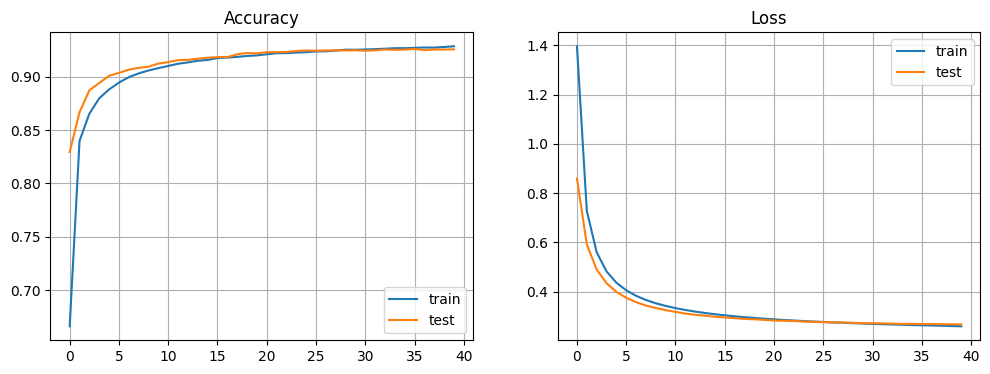

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 13.3409 secs
Accuracy = 0.9257
Confusion matrix
[[ 962    0    2    1    0    5    5    3    2    0]
 [   0 1113    3    2    0    2    4    2    9    0]
 [   7    9  922   17   10    4   13    9   37    4]
 [   4    1   19  917    1   25    2   12   21    8]
 [   1    1    2    2  918    0   12    4   10   32]
 [   8    3    3   29   10  781   14    7   29    8]
 [  10    3    7    1    7   13  914    2    1    0]
 [   1    7   22    7    6    0    0  950    2   33]
 [   7    9    6   20    9   28   10   14  865    6]
 [  11    6    1   10   31    7    0   23    5  915]]


In [37]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40,
    batch_size = 1000,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))

# **Exercises**

## Exercise 1.

Evaluate the performance of linear regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 2s - 37ms/step - accuracy: 0.6503 - loss: 0.0991 - val_accuracy: 0.8137 - val_loss: 0.0510
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.8169 - loss: 0.0475 - val_accuracy: 0.8379 - val_loss: 0.0442
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.8348 - loss: 0.0435 - val_accuracy: 0.8473 - val_loss: 0.0421
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.8419 - loss: 0.0417 - val_accuracy: 0.8526 - val_loss: 0.0408
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.8448 - loss: 0.0408 - val_accuracy: 0.8497 - val_loss: 0.0403
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.8471 - loss: 0.0402 - val_accuracy: 0.8538 - val_loss: 0.0398
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.8489 - loss: 0.0399 - val_accuracy: 0.8517 - val_loss: 0.0397
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.8504 - loss: 0.0397 - val_accuracy: 0.8568 - val_loss: 0.0396
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.8501 - loss: 0.0395 - val_accuracy: 0.8563 - val_loss: 0.0394
Epoch 10/40
60/60 

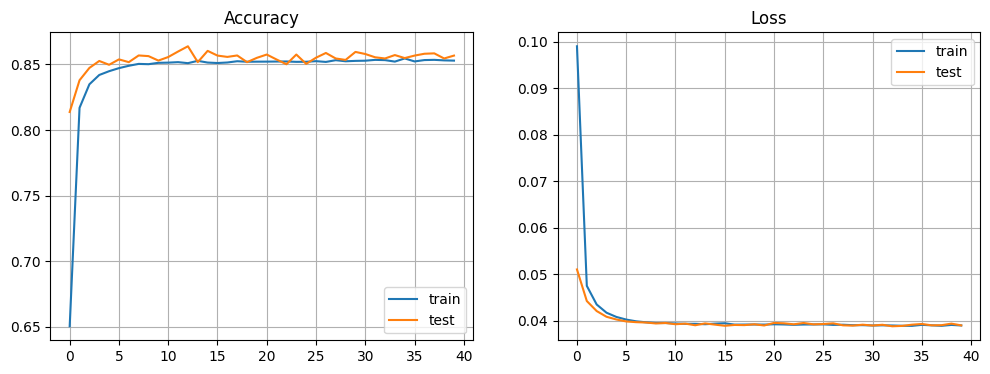

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 13.5808 secs
Accuracy = 0.8567
Confusion matrix
[[ 944    1    2    2    2   12    8    2    6    1]
 [   0 1111    2    1    1    1    5    1   13    0]
 [  21   63  798   26   17    0   39   25   38    5]
 [   5   18   25  877    6   22    6   23   18   10]
 [   0   25    8    0  879    6    6    3   11   44]
 [  23   19    3   67   20  684   17   13   32   14]
 [  27   10   14    0   26   21  849    0   11    0]
 [   5   43   15    6   23    1    1  889    1   44]
 [  16   50   10   31   28   45   16   14  748   16]
 [  16   13    2   16   81    2    1   84    6  788]]


In [38]:
def linear_regression_2layers(n_inputs=784, n_hidden=128, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(n_hidden))   # extra dense layer
  model.add(Dense(n_outputs))  # output layer
  return model

model = linear_regression_2layers(x_train.shape[1], 128, y_train.shape[1])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(), loss="mse", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs=40,
    batch_size=1000,
    verbose=2,
    validation_data=(x_test, y_test),
)
end_train = time.time()

plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred, axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int, np.argmax(y_test, axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test, axis=1), pred_int))

# Exercise 1 conclusion:
# Adding another dense layer did not improve linear regression. In our output, the
# accuracy stayed about the same and was slightly worse than the original model.
# This makes sense because both Dense layers are linear, so stacking them is still
# just one linear transformation. Therefore, the model does not gain real extra
# expressive power unless we add a nonlinear activation.

## Exercise 2.

Evaluate the performance of logistic regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_5 (Softmax)             │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 3s - 43ms/step - accuracy: 0.8013 - loss: 0.7116 - val_accuracy: 0.9008 - val_loss: 0.3610
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.9042 - loss: 0.3414 - val_accuracy: 0.9136 - val_loss: 0.3055
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.9145 - loss: 0.3030 - val_accuracy: 0.9204 - val_loss: 0.2850
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.9200 - loss: 0.2862 - val_accuracy: 0.9222 - val_loss: 0.2758
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.9223 - loss: 0.2776 - val_accuracy: 0.9249 - val_loss: 0.2716
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.9245 - loss: 0.2702 - val_accuracy: 0.9237 - val_loss: 0.2718
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.9262 - loss: 0.2656 - val_accuracy: 0.9254 - val_loss: 0.2682
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9270 - loss: 0.2607 - val_accuracy: 0.9250 - val_loss: 0.2667
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9283 - loss: 0.2578 - val_accuracy: 0.9264 - val_loss: 0.2650
Epoch 10/40
60/60 

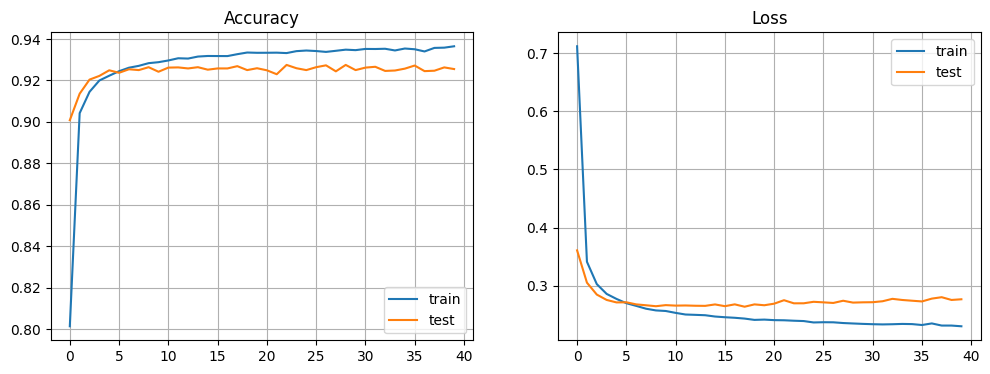

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 13.9207 secs
Accuracy = 0.9255
Confusion matrix
[[ 955    0    0    2    2    9    7    4    1    0]
 [   0 1107    4    2    0    2    3    2   15    0]
 [   6    6  912   17   10    3   12   11   52    3]
 [   2    0   14  924    1   22    4   10   26    7]
 [   1    1    6    3  915    0    7    7    8   34]
 [   8    2    3   34    9  774   13    9   36    4]
 [  11    3    7    2    7   11  914    1    2    0]
 [   0    6   23    5    4    1    0  955    4   30]
 [   6    5    3   22    7   26    8   11  879    7]
 [   8    6    1    8   24    6    0   23   13  920]]


In [39]:
def logistic_regression_2layers(n_inputs=784, n_hidden=128, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(n_hidden))   # extra dense layer
  model.add(Dense(n_outputs))
  model.add(Softmax())
  return model

model = logistic_regression_2layers(x_train.shape[1], 128, y_train.shape[1])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(), loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs=40,
    batch_size=1000,
    verbose=2,
    validation_data=(x_test, y_test),
)
end_train = time.time()

plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred, axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int, np.argmax(y_test, axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test, axis=1), pred_int))

# Exercise 2 conclusion:
# Adding another dense layer did not produce a meaningful improvement in logistic
# regression. The accuracy changed only slightly, which is most likely due to random
# initialization/training variation. This is expected because logistic regression is
# based on a linear score z = w·x + b followed by sigmoid/softmax, and adding another
# Dense layer without a nonlinear activation is still just another linear map before
# softmax, so the model is effectively still logistic regression.